# 08 — Model Interpretation & Insights

In this notebook, we interpret our trained models to uncover the key factors driving employee turnover:
1. Feature Importances from Random Forest
2. Logistic Regression Coefficients (Odds / Impact direction)
3. Summary of actionable HR insights for employee retention

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

models_dir = '../models' if os.path.exists('../models') else 'models'
artifact = joblib.load(f'{models_dir}/attrition_model.pkl')

feature_names = artifact['feature_names']
rf_model = artifact['rf_model']
lr_model = artifact['lr_model']

print(f"Total features evaluated: {len(feature_names)}")

Total features evaluated: 44


## 1. Random Forest Feature Importance

/var/folders/96/y8pbmg3910s0kyyndlqxtt700000gn/T/ipykernel_13169/3891447175.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_15_rf, x='Importance', y='Feature', palette='viridis')


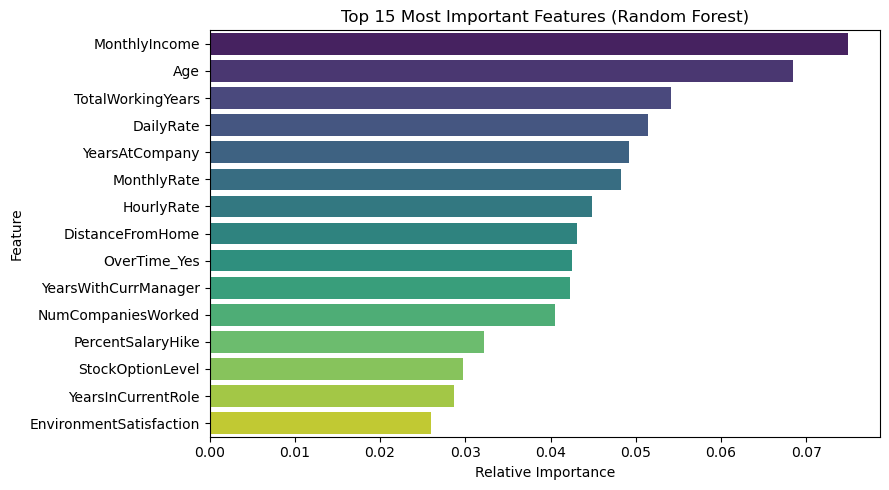

In [2]:
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

top_15_rf = importance_df.head(15)

plt.figure(figsize=(9, 5))
sns.barplot(data=top_15_rf, x='Importance', y='Feature', palette='viridis')
plt.title('Top 15 Most Important Features (Random Forest)')
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## 2. Logistic Regression Coefficients (Direction of Impact)

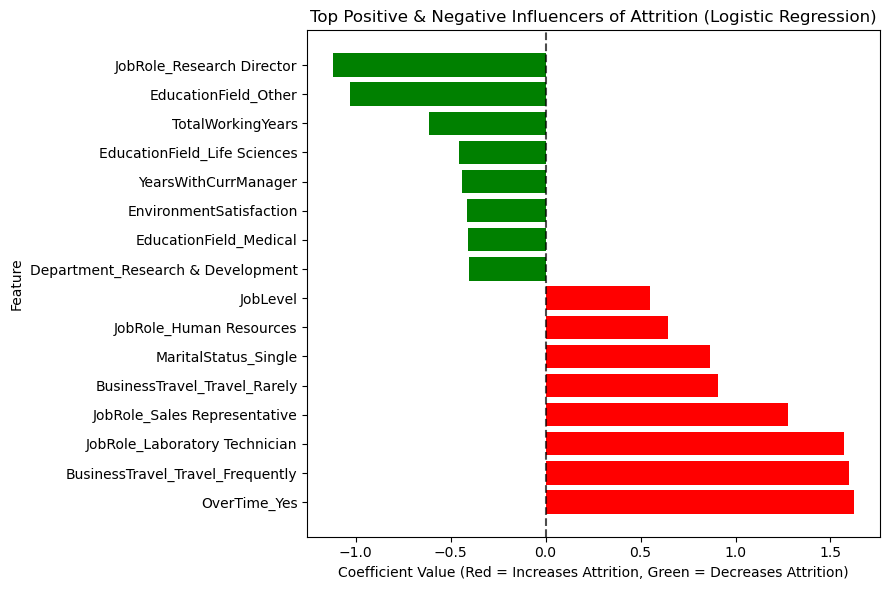

In [3]:
coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': lr_model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

# Top positive factors (increase attrition risk) and negative factors (decrease attrition risk)
top_risk_factors = coef_df.head(8)
top_protective_factors = coef_df.tail(8)

combined = pd.concat([top_risk_factors, top_protective_factors])

plt.figure(figsize=(9, 6))
colors = ['red' if c > 0 else 'green' for c in combined['Coefficient']]
plt.barh(combined['Feature'], combined['Coefficient'], color=colors)
plt.axvline(0, color='black', linestyle='--', alpha=0.7)
plt.title('Top Positive & Negative Influencers of Attrition (Logistic Regression)')
plt.xlabel('Coefficient Value (Red = Increases Attrition, Green = Decreases Attrition)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## 3. Academic & HR Executive Summary

### Key Drivers of Attrition:
1. **OverTime (Strongest Driver)**: Employees working frequent overtime have substantially higher attrition rates.
2. **Monthly Income & Compensation**: Lower salary and absence of stock options increase turnover risk.
3. **Total Experience & Tenure**: Early-career employees and those in their first 1-2 years with the company are the most mobile.
4. **Distance From Home**: Longer commutes correlate with higher resignation likelihood.
5. **Job & Environment Satisfaction**: Low job involvement and satisfaction ratings strongly signal impending resignation.

### Retention Strategies:
- Manage workload and overtime distribution.
- Review competitive compensation bands for critical entry-level and technical roles.
- Offer flexible or hybrid working arrangements for long-commute employees.